In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder , StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron    # Used for simple linear classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential     # Sequential lets you build a neural network layer-by-layer in Keras.

from tensorflow.keras.layers import Dense     #Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D     # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout          # Dropout prevents overfitting

from tensorflow.keras.utils import to_categorical     # converts numeric class labels into one-hot encoded format for training classification models
     

In [4]:
df = pd.read_csv("cnn_digit_dataset.csv")

In [5]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df["label"].value_counts()

label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64

In [7]:
df.shape

(10000, 785)

In [8]:
X = df.drop("label",axis=1).values
y = df["label"].values 

In [9]:
X = X.astype("float") / 255.0

In [10]:
# scaler = StandardScaler()
# X = scaler.fit_transform(X)

# Reshaping the dataset for using all the columns together 
X = X.reshape(-1,28,28)

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)

In [12]:
X_train

array([[[0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        , ..., 0.00392157,
         0.01960784, 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ]],

       [[0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0. 

In [13]:
y_train_cat = to_categorical(y_train,10)
y_test_cat = to_categorical(y_test,10)

In [14]:
# Perceptron model training 

perceptron = Sequential([
    Flatten(input_shape = (28,28)),
    Dense(10,activation="softmax")
])

In [15]:
perceptron

<Sequential name=sequential, built=True>

In [16]:
perceptron.compile(optimizer="sgd",loss="categorical_crossentropy",metrics=["accuracy"])

In [17]:
history_per = perceptron.fit(
    X_train,y_train_cat,
    epochs = 50 , batch_size = 32,
    validation_data = (X_test,y_test_cat),
    verbose = 1
)

Epoch 1/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2380 - loss: 2.1806 - val_accuracy: 0.3715 - val_loss: 2.0051
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4471 - loss: 1.9030 - val_accuracy: 0.5095 - val_loss: 1.7865
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5319 - loss: 1.7309 - val_accuracy: 0.5515 - val_loss: 1.6442
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5742 - loss: 1.6138 - val_accuracy: 0.5900 - val_loss: 1.5447
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5972 - loss: 1.5293 - val_accuracy: 0.6155 - val_loss: 1.4708
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6074 - loss: 1.4650 - val_accuracy: 0.6275 - val_loss: 1.4138
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6216 - loss: 1.4135 - val_accuracy: 0.6425 - val_loss: 1.3678
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6319 - loss: 1.3717 - val_accuracy: 0.

In [18]:
acc_per = perceptron.evaluate(X_test,y_test_cat,verbose = 1)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7160 - loss: 0.9829


In [19]:
acc_per[1]

0.7160000205039978

In [20]:
# ANN

ann = Sequential([
    Flatten(input_shape = (28,28)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])

In [21]:
ann.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])

In [22]:
history_ann = ann.fit(
    X_train,y_train_cat,
    validation_data = (X_test,y_test_cat),
    epochs = 100 , verbose = 1, batch_size = 50
)

Epoch 1/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6014 - loss: 1.2708 - val_accuracy: 0.7670 - val_loss: 0.7548
Epoch 2/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7770 - loss: 0.6810 - val_accuracy: 0.7975 - val_loss: 0.5903
Epoch 3/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8096 - loss: 0.5679 - val_accuracy: 0.8140 - val_loss: 0.5252
Epoch 4/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8334 - loss: 0.5032 - val_accuracy: 0.8280 - val_loss: 0.4750
Epoch 5/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8545 - loss: 0.4445 - val_accuracy: 0.8400 - val_loss: 0.4376
Epoch 6/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8789 - loss: 0.3901 - val_accuracy: 0.8590 - val_loss: 0.4023
Epoch 7/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8990 - loss: 0.3363 - val_accuracy: 0.8640 - val_loss: 0.3661
Epoch 8/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9139 - loss: 0.2914 - val_accu

In [23]:
acc_ann = ann.evaluate(X_test,y_test_cat,verbose = 1)[1]

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9595 - loss: 0.2635


In [24]:
acc_ann

0.9595000147819519

In [34]:
X_train_cnn = X_train.reshape(-1,28,28,1)
X_test_cnn = X_test.reshape(-1,28,28,1)

In [27]:
# CNN

cnn = Sequential([
    Conv2D(32,kernel_size = (3,3),activation = "relu" , input_shape = (28,28,1)),
    MaxPooling2D(pool_size = (2,2)),
    Conv2D(64,kernel_size = (3,3),activation = "relu"),
    MaxPooling2D(pool_size = (2,2)),
    Flatten(),
    Dense(128,activation = "relu"),
    Dropout(0.5),
    Dense(10,activation = "softmax")
])

In [29]:
cnn.compile(optimizer = "adam",loss = "categorical_crossentropy",metrics = ["accuracy"])

In [31]:
history_cnn = cnn.fit(
    X_train_cnn,y_train_cat,
    validation_data = (X_test,y_test_cat),
    epochs = 100 , batch_size = 50 , verbose = 1
)

Epoch 1/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.5621 - loss: 1.2434 - val_accuracy: 0.8225 - val_loss: 0.5521
Epoch 2/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8004 - loss: 0.5727 - val_accuracy: 0.8720 - val_loss: 0.3940
Epoch 3/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.8570 - loss: 0.4159 - val_accuracy: 0.9250 - val_loss: 0.2548
Epoch 4/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8945 - loss: 0.3027 - val_accuracy: 0.9440 - val_loss: 0.1851
Epoch 5/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9234 - loss: 0.2274 - val_accuracy: 0.9775 - val_loss: 0.1129
Epoch 6/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9485 - loss: 0.1602 - val_accuracy: 0.9815 - val_loss: 0.0733
Epoch 7/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9660 - loss: 0.1134 - val_accuracy: 0.9840 - val_loss: 0.0648
Epoch 8/100
160/160 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9675 - loss: 0.1049 - 

In [32]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

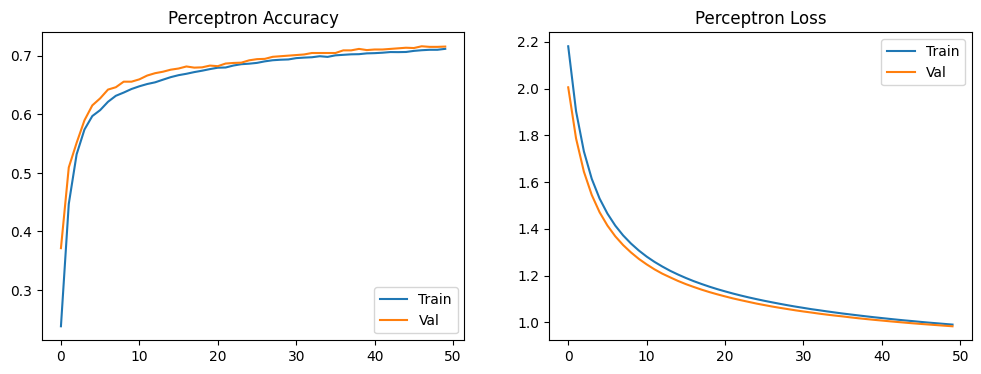

In [36]:
plot_training(history_per, "Perceptron")

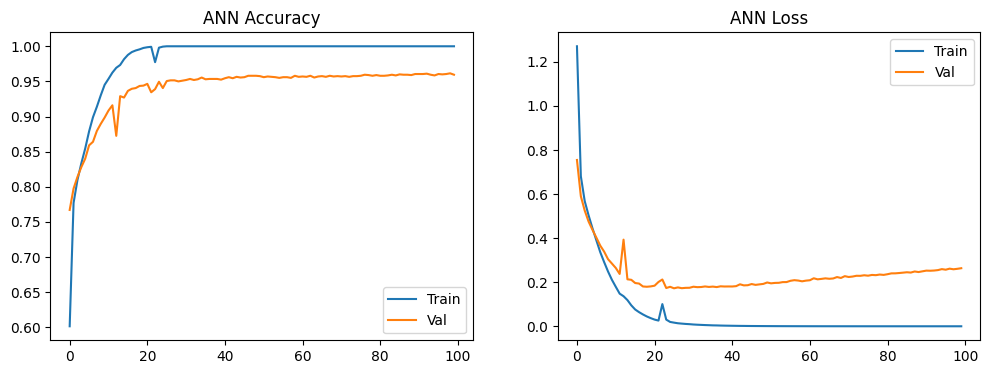

In [37]:
plot_training(history_ann, "ANN")

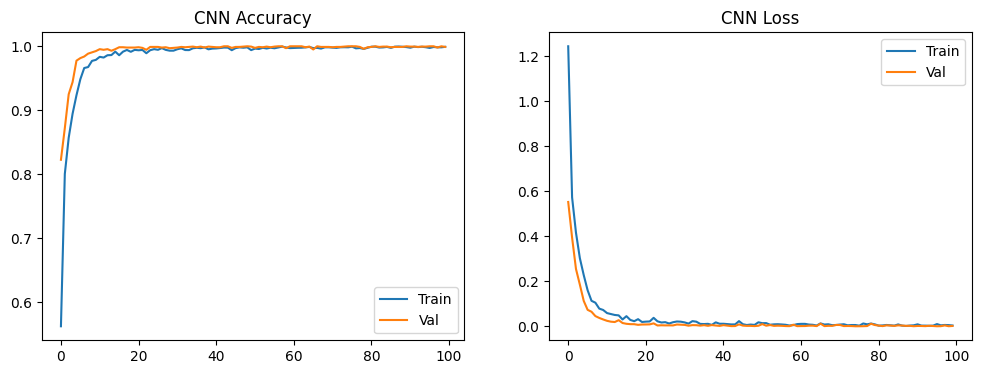

In [38]:
plot_training(history_cnn, "CNN")

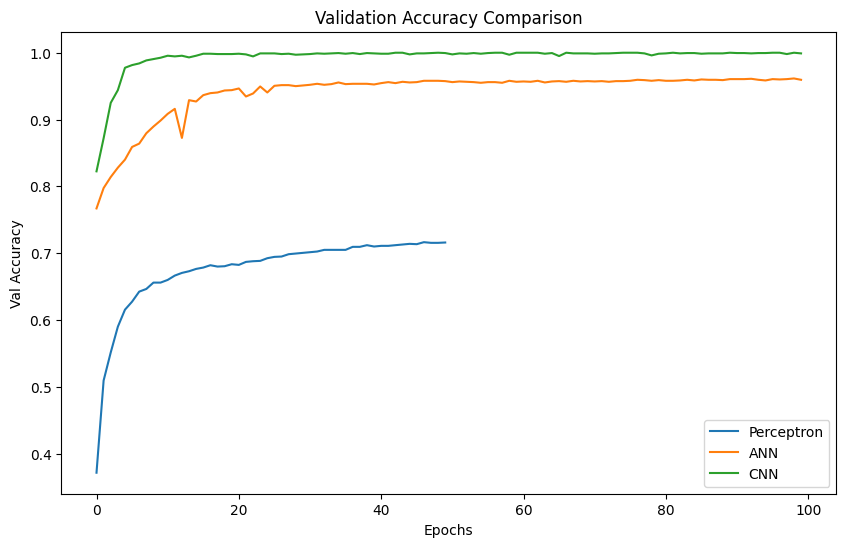

In [40]:
plt.figure(figsize=(10,6))
plt.plot(history_per.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [41]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()
     

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


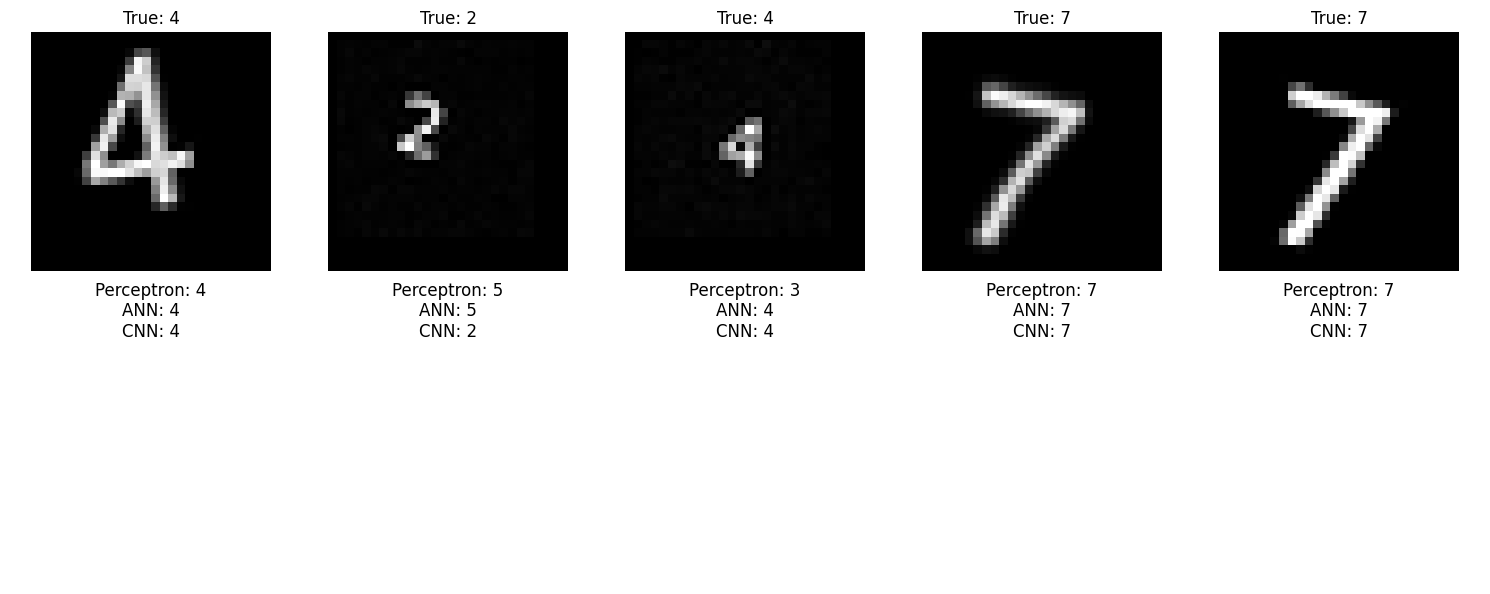

In [49]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test, X_test_cnn, y_test, 5)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


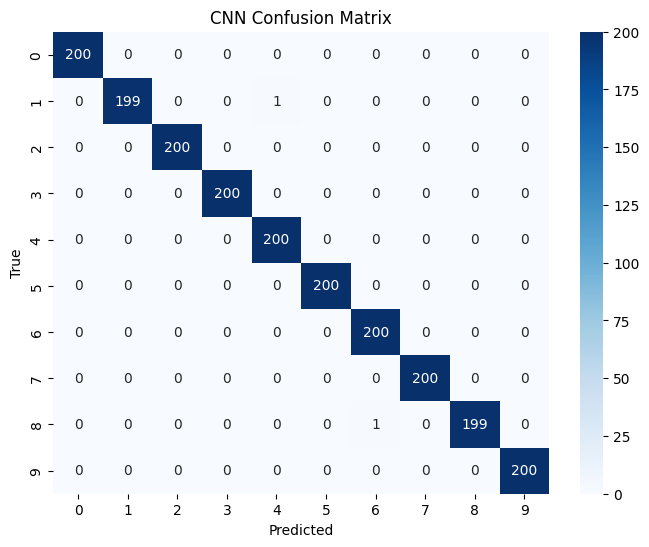

In [44]:
y_pred_cnn = np.argmax(cnn.predict(X_test_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()